In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import iqr

# Part c

In [2]:
def g(z, x):
    alpha, b = z
    beta = np.e ** b
    n = len(x)

    f = (beta ** (n - 1)) / (np.pi ** n)
    product = 1
    for x_i in x:
        term = 1 / (beta**2 + (x_i - alpha)**2)
        product = product * term
    return(f*product* (np.e**b))

In [3]:
def MCMC(s):
    z = np.array([0,0])
    timesteps = 5 * (10**4)
    x = np.array([-1.77, 2.47, 1.34, 2.18, 13.05, 1.60, 1.50, -1.97,
                0.79, 1.50, 2.00, 2.63, 1.19, -2.31, 0.87])

    acceptances = 0
    z_vals = np.empty((0,2))
    for t in range(timesteps):
        epsilon = np.random.standard_normal(2)
        proposal = z + s * epsilon
        accept_prob = min(1,  g(proposal,x) / g(z,x))
        accept = np.random.binomial(1,accept_prob)
        if accept == 1:
            z = proposal
            acceptances += 1
        z_vals = np.vstack((z_vals, z))

    # integrated autocorrelation time of alpha (FFT-based autocovariance)
    a = z_vals[:, 0] - z_vals[:, 0].mean()
    n = len(a)
    f = np.fft.rfft(a, 2 * n)
    acov = np.fft.irfft(f * np.conj(f))[:n] / n
    rho = acov / acov[0]
    # sum autocorrelations until the first non-positive value
    cut = np.argmax(rho < 0) if np.any(rho < 0) else n
    tau = 1 + 2 * rho[1:cut].sum()

    print(acceptances / timesteps, tau)

    return(z_vals)

0.96562 1596.5997482284863
0.3671 7.141621050958407
0.00878 130.77804474627172


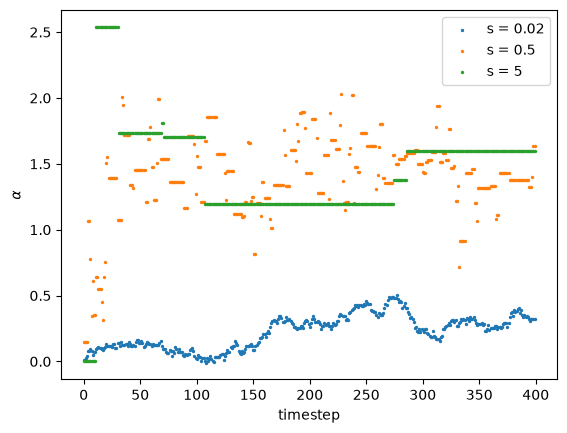

In [4]:
z_vals1 = MCMC(0.02)
z_vals2 = MCMC(0.5)
z_vals3 = MCMC(5)

plt.scatter(range(400), z_vals1[0:400,0], label = "s = 0.02",s = 2)
plt.scatter(range(400), z_vals2[0:400,0], label = "s = 0.5",s = 2)
plt.scatter(range(400), z_vals3[0:400,0], label = "s = 5",s = 2)
plt.xlabel("timestep")
plt.ylabel(r"$\alpha$")
plt.legend()
plt.savefig("/Users/viro3403/Library/CloudStorage/OneDrive-UCB-O365/Desktop/Markov/HW7/hw7_p1_plot1.png")

/var/folders/wq/n6jdzq2n3d5bg5tqzyfp4cw00000gp/T/ipykernel_49111/1102972221.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(markerscale=8)


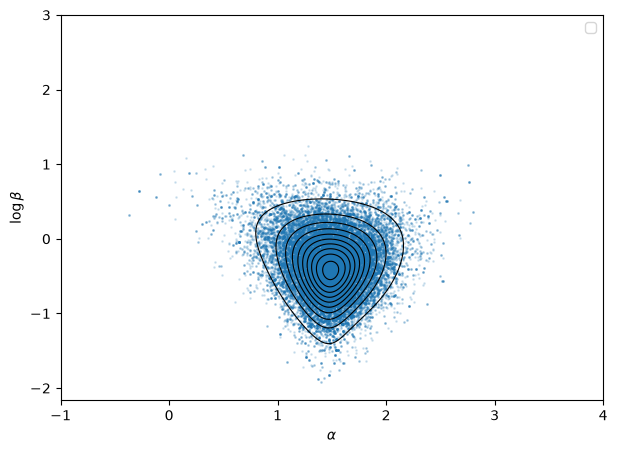

In [6]:
import numpy as np
import matplotlib.pyplot as plt

samples = z_vals2[5000:]
x = np.array([-1.77, 2.47, 1.34, 2.18, 13.05, 1.60, 1.50, -1.97,
            0.79, 1.50, 2.00, 2.63, 1.19, -2.31, 0.87])

alpha_grid = np.linspace(-1, 4, 400)
b_grid = np.linspace(-1.5, 3, 400)
A, B = np.meshgrid(alpha_grid, b_grid)

logG = len(x) * B - np.sum(
    np.log(np.exp(2 * B)[..., None] + (x - A[..., None])**2), axis=-1
)
G = np.exp(logG - logG.max())

plt.figure(figsize=(7, 5))
plt.scatter(samples[:, 0], samples[:, 1], s=1, alpha=0.15)
plt.contour(A, B, G, levels=np.linspace(0.05, 0.95, 10) * G.max(), colors="k", linewidths=0.8)
plt.xlabel(r"$\alpha$")
plt.ylabel(r"$\log \beta$")
plt.legend(markerscale=8)
plt.savefig("/Users/viro3403/Library/CloudStorage/OneDrive-UCB-O365/Desktop/Markov/HW7/hw7_p1_plot2.png")

Computing summary statistics

In [7]:
alpha_s = samples[:, 0]
beta_s = np.exp(samples[:, 1])
print("Chain")
for name, v in [("alpha", alpha_s), ("beta", beta_s)]:
    lo, hi = np.percentile(v, [5, 95])
    print(f"{name}: mean = {v.mean():.3f}, 90% interval = ({lo:.3f}, {hi:.3f})")

W = G / G.sum()                   
w_alpha = W.sum(axis=0)  
w_b = W.sum(axis=1)

def grid_summary(values, w):
    mean = np.sum(values * w)
    cdf = np.cumsum(w)
    lo = np.interp(0.05, cdf, values)
    hi = np.interp(0.95, cdf, values)
    return mean, lo, hi

beta_grid = np.exp(b_grid)   
print("Grid")
for name, vals, w in [("alpha", alpha_grid, w_alpha), ("beta", beta_grid, w_b)]:
    m, lo, hi = grid_summary(vals, w)
    print(f"{name}: mean = {m:.3f}, 90% interval = ({lo:.3f}, {hi:.3f})")

Chain
alpha: mean = 1.480, 90% interval = (1.033, 1.925)
beta: mean = 0.769, 90% interval = (0.374, 1.378)
Grid
alpha: mean = 1.483, 90% interval = (1.024, 1.927)
beta: mean = 0.777, 90% interval = (0.375, 1.375)


In [8]:
print(f"mean = {np.mean(x):.3f}, median = {np.median(x):.3f}")

mean = 1.671, median = 1.500


# Part d

In [33]:
rng = np.random.default_rng()
alpha, beta = 1.5, 0.8

for n in [10, 100, 1000]:
    u = rng.uniform(size=(2000, n))
    X = alpha + beta * np.tan(np.pi * (u - 0.5))   # inverse CDF
    means, medians = X.mean(axis=1), np.median(X, axis=1)
    print(f"n = {n}: iqr of mean = {iqr(means):.3f}, iqr of median = {iqr(medians):.3f}")

n = 10: iqr of mean = 1.601, iqr of median = 0.527
n = 100: iqr of mean = 1.635, iqr of median = 0.171
n = 1000: iqr of mean = 1.684, iqr of median = 0.053
